In [1]:
import pandas as pd
import numpy as np

# Load the customer shopping dataset
df = pd.read_csv("customer_shopping_behavior.csv")

# Display the first 5 rows
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [2]:
# 1. Check total rows and columns
print("Dataset Shape:", df.shape)

# 2. Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (3900, 18)

Column Names:
['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color            

In [3]:
# Check unique customer IDs
print("Total Customer IDs:", df['Customer ID'].nunique())

# Check duplicate customer IDs
print("Duplicate Customer IDs:", df['Customer ID'].duplicated().sum())

# Statistical summary of numerical columns
df.describe()

Total Customer IDs: 3900
Duplicate Customer IDs: 0


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [4]:
# Review rating distribution
print("Review Rating Distribution:")
print(df['Review Rating'].value_counts().sort_index())

# Check missing rating records
print("\nRecords with Missing Ratings:")
display(df[df['Review Rating'].isnull()].head(10))

# Percentage of missing ratings
print("\nMissing Rating Percentage:")
print(round(df['Review Rating'].isnull().mean() * 100, 2), "%")

Review Rating Distribution:
Review Rating
2.5     66
2.6    158
2.7    154
2.8    136
2.9    166
3.0    162
3.1    156
3.2    152
3.3    146
3.4    182
3.5    152
3.6    147
3.7    149
3.8    141
3.9    162
4.0    181
4.1    148
4.2    169
4.3    147
4.4    158
4.5    139
4.6    170
4.7    148
4.8    144
4.9    162
5.0     68
Name: count, dtype: int64

Records with Missing Ratings:


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
38,39,29,Male,Dress,Clothing,37,Florida,M,Red,Winter,NaN,Yes,2-Day Shipping,Yes,Yes,44,Venmo,Every 3 Months
50,51,49,Male,Blouse,Clothing,28,Maryland,M,Red,Spring,NaN,Yes,Store Pickup,Yes,Yes,39,Debit Card,Bi-Weekly
80,81,19,Male,Sandals,Footwear,72,New York,XL,Blue,Summer,NaN,Yes,Store Pickup,Yes,Yes,24,Credit Card,Every 3 Months
96,97,32,Male,Gloves,Accessories,73,Delaware,S,Gold,Spring,NaN,Yes,Express,Yes,Yes,43,Venmo,Every 3 Months
262,263,37,Male,Pants,Clothing,40,Hawaii,M,Teal,Summer,NaN,Yes,Next Day Air,Yes,Yes,6,Debit Card,Annually
330,331,46,Male,Sweater,Clothing,51,North Dakota,M,Beige,Winter,NaN,Yes,Express,Yes,Yes,43,Venmo,Bi-Weekly
356,357,56,Male,Pants,Clothing,80,Nevada,L,Black,Spring,NaN,Yes,Standard,Yes,Yes,27,Cash,Weekly
383,384,50,Male,Sunglasses,Accessories,77,West Virginia,S,Magenta,Fall,NaN,Yes,Standard,Yes,Yes,6,PayPal,Quarterly
419,420,53,Male,Shorts,Clothing,91,Utah,S,Teal,Winter,NaN,Yes,Free Shipping,Yes,Yes,14,Credit Card,Every 3 Months
442,443,29,Male,Sunglasses,Accessories,69,Michigan,M,Olive,Fall,NaN,Yes,Store Pickup,Yes,Yes,31,Credit Card,Quarterly



Missing Rating Percentage:
0.95 %


In [5]:
# Check numerical value ranges

print("Age Range:")
print(df['Age'].min(), "-", df['Age'].max())

print("\nPurchase Amount Range:")
print(df['Purchase Amount (USD)'].min(), "-", df['Purchase Amount (USD)'].max())

print("\nPrevious Purchases Range:")
print(df['Previous Purchases'].min(), "-", df['Previous Purchases'].max())

print("\nReview Rating Range:")
print(df['Review Rating'].min(), "-", df['Review Rating'].max())

# Check invalid values
print("\nInvalid Ages:", ((df['Age'] < 18) | (df['Age'] > 100)).sum())

print("Invalid Purchase Amounts:", (df['Purchase Amount (USD)'] <= 0).sum())

print("Invalid Ratings:", ((df['Review Rating'] < 1) | (df['Review Rating'] > 5)).sum())

Age Range:
18 - 70

Purchase Amount Range:
20 - 100

Previous Purchases Range:
1 - 50

Review Rating Range:
2.5 - 5.0

Invalid Ages: 0
Invalid Purchase Amounts: 0
Invalid Ratings: 0


In [6]:
# Identify text columns
text_columns = df.select_dtypes(include=['str', 'object']).columns

# Display unique values in each text column
for col in text_columns:
    print(f"\n{col}")
    print("Unique values:", sorted(df[col].dropna().unique()))

# Check for leading or trailing spaces
print("\nChecking for extra spaces:")

for col in text_columns:
    extra_spaces = df[col].dropna().str.strip().ne(df[col].dropna()).sum()
    print(f"{col}: {extra_spaces}")


Gender
Unique values: ['Female', 'Male']

Item Purchased
Unique values: ['Backpack', 'Belt', 'Blouse', 'Boots', 'Coat', 'Dress', 'Gloves', 'Handbag', 'Hat', 'Hoodie', 'Jacket', 'Jeans', 'Jewelry', 'Pants', 'Sandals', 'Scarf', 'Shirt', 'Shoes', 'Shorts', 'Skirt', 'Sneakers', 'Socks', 'Sunglasses', 'Sweater', 'T-shirt']

Category
Unique values: ['Accessories', 'Clothing', 'Footwear', 'Outerwear']

Location
Unique values: ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washing

In [7]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Keep missing Review Rating values as they are
# We will not replace them with invented ratings

# Check the cleaned dataset
print("\nCleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:", df_clean.duplicated().sum())

Missing values before cleaning:
Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

Cleaned dataset shape: (3900, 18)

Missing values after cleaning:
Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type     

In [8]:
# Create customer age groups
df_clean['Age Group'] = pd.cut(
    df_clean['Age'],
    bins=[17, 25, 35, 45, 55, 70],
    labels=['18-25', '26-35', '36-45', '46-55', '56-70']
)

# Create purchase amount categories
df_clean['Purchase Category'] = pd.cut(
    df_clean['Purchase Amount (USD)'],
    bins=[0, 25, 50, 75, 100],
    labels=['Low', 'Medium', 'High', 'Premium'],
    include_lowest=True
)

# Display the new columns
df_clean[['Age', 'Age Group',
          'Purchase Amount (USD)', 'Purchase Category']].head(10)

,Age,Age Group,Purchase Amount (USD),Purchase Category
0,55,46-55,53,High
1,19,18-25,64,High
2,50,46-55,73,High
3,21,18-25,90,Premium
4,45,36-45,49,Medium
5,46,46-55,20,Low
6,63,56-70,85,Premium
7,27,26-35,34,Medium
8,26,26-35,97,Premium
9,57,56-70,31,Medium


In [9]:
# Count customers in each age group
print("Customers by Age Group:")
print(df_clean['Age Group'].value_counts().sort_index())

# Count purchases in each spending category
print("\nPurchases by Purchase Category:")
print(df_clean['Purchase Category'].value_counts().sort_index())

# Check for missing values in the new columns
print("\nMissing values in new columns:")
print(df_clean[['Age Group', 'Purchase Category']].isnull().sum())

Customers by Age Group:
Age Group
18-25     571
26-35     742
36-45     729
46-55     753
56-70    1105
Name: count, dtype: int64

Purchases by Purchase Category:
Purchase Category
Low         305
Medium     1209
High       1172
Premium    1214
Name: count, dtype: int64

Missing values in new columns:
Age Group            0
Purchase Category    0
dtype: int64


In [10]:
# Overall business metrics

print("CUSTOMER SHOPPING BEHAVIOR - BUSINESS OVERVIEW")
print("-" * 50)

print("Total Customers:", df_clean['Customer ID'].nunique())

print("Total Recorded Purchase Amount ($):",
      df_clean['Purchase Amount (USD)'].sum())

print("Average Purchase Amount ($):",
      round(df_clean['Purchase Amount (USD)'].mean(), 2))

print("Median Purchase Amount ($):",
      df_clean['Purchase Amount (USD)'].median())

print("Average Customer Age:",
      round(df_clean['Age'].mean(), 2))

print("Average Review Rating:",
      round(df_clean['Review Rating'].mean(), 2))

print("Subscribed Customers:",
      (df_clean['Subscription Status'] == 'Yes').sum())

print("Non-Subscribed Customers:",
      (df_clean['Subscription Status'] == 'No').sum())

CUSTOMER SHOPPING BEHAVIOR - BUSINESS OVERVIEW
--------------------------------------------------
Total Customers: 3900
Total Recorded Purchase Amount ($): 233081
Average Purchase Amount ($): 59.76
Median Purchase Amount ($): 60.0
Average Customer Age: 44.07
Average Review Rating: 3.75
Subscribed Customers: 1053
Non-Subscribed Customers: 2847


In [11]:
# Purchase amount by product category

category_analysis = df_clean.groupby('Category').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

category_analysis['Total_Purchase_Amount'] = (
    category_analysis['Total_Purchase_Amount'].round(2)
)

category_analysis['Average_Purchase_Amount'] = (
    category_analysis['Average_Purchase_Amount'].round(2)
)

category_analysis = category_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

category_analysis

,Category,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
1,Clothing,1737,104264,60.03
0,Accessories,1240,74200,59.84
2,Footwear,599,36093,60.26
3,Outerwear,324,18524,57.17


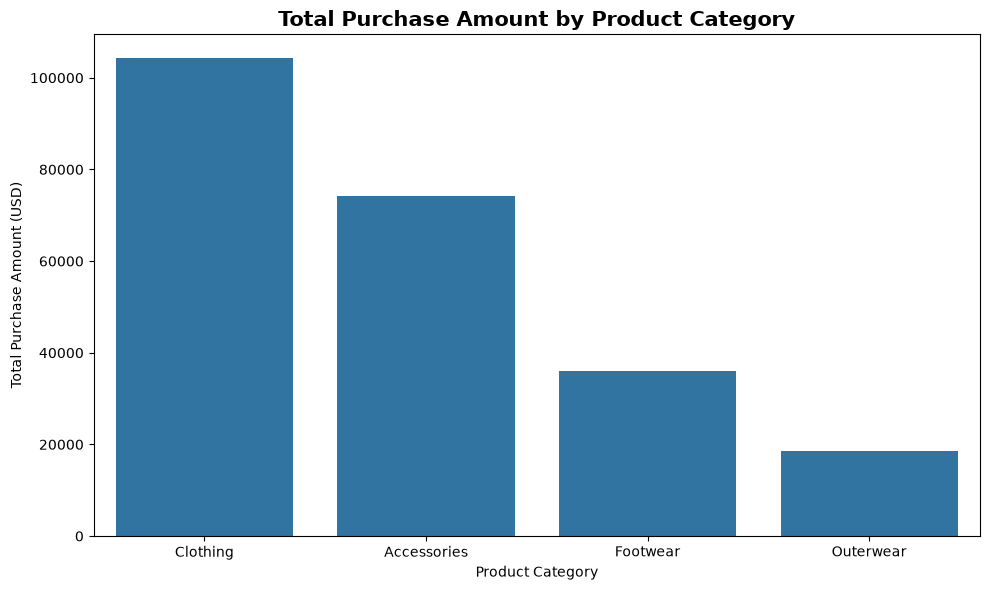

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x='Category',
    y='Total_Purchase_Amount'
)

plt.title('Total Purchase Amount by Product Category',
          fontsize=15, fontweight='bold')

plt.xlabel('Product Category')
plt.ylabel('Total Purchase Amount (USD)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Purchase analysis by gender

gender_analysis = df_clean.groupby('Gender').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

gender_analysis['Average_Purchase_Amount'] = (
    gender_analysis['Average_Purchase_Amount'].round(2)
)

gender_analysis = gender_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

gender_analysis

,Gender,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
1,Male,2652,157890,59.54
0,Female,1248,75191,60.25


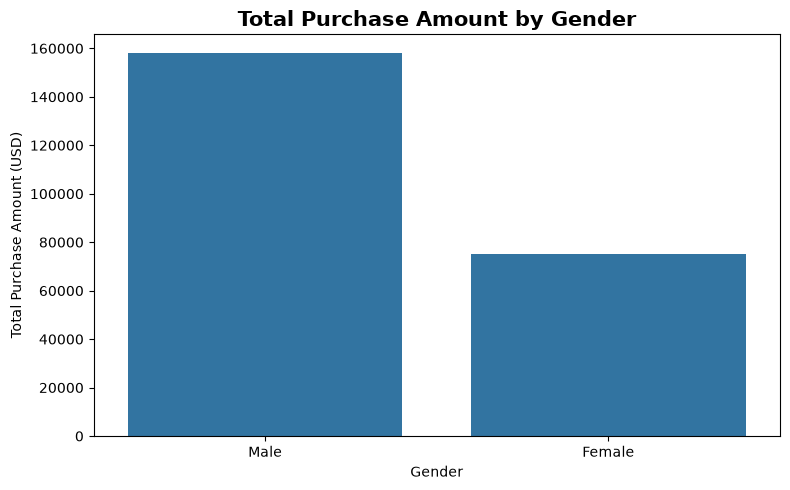

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_analysis,
    x='Gender',
    y='Total_Purchase_Amount'
)

plt.title('Total Purchase Amount by Gender',
          fontsize=15, fontweight='bold')

plt.xlabel('Gender')
plt.ylabel('Total Purchase Amount (USD)')

plt.tight_layout()
plt.show()

In [15]:
# Purchase analysis by age group

age_analysis = df_clean.groupby('Age Group', observed=True).agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

age_analysis['Average_Purchase_Amount'] = (
    age_analysis['Average_Purchase_Amount'].round(2)
)

age_analysis = age_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

age_analysis

,Age Group,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
4,56-70,1105,65256,59.06
3,46-55,753,45619,60.58
1,26-35,742,44342,59.76
2,36-45,729,43234,59.31
0,18-25,571,34630,60.65


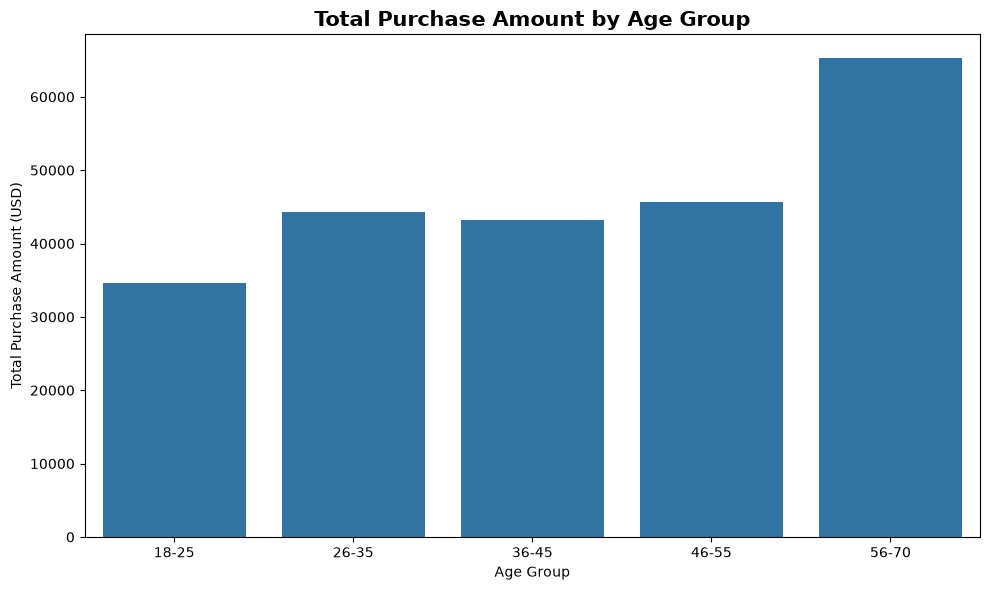

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_analysis,
    x='Age Group',
    y='Total_Purchase_Amount'
)

plt.title('Total Purchase Amount by Age Group',
          fontsize=15, fontweight='bold')

plt.xlabel('Age Group')
plt.ylabel('Total Purchase Amount (USD)')

plt.tight_layout()
plt.show()

In [17]:
# Subscription behaviour analysis

subscription_analysis = df_clean.groupby('Subscription Status').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean'),
    Average_Review_Rating=('Review Rating', 'mean')
).reset_index()

subscription_analysis['Average_Purchase_Amount'] = (
    subscription_analysis['Average_Purchase_Amount'].round(2)
)

subscription_analysis['Average_Review_Rating'] = (
    subscription_analysis['Average_Review_Rating'].round(2)
)

subscription_analysis

,Subscription Status,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount,Average_Review_Rating
0,No,2847,170436,59.87,3.75
1,Yes,1053,62645,59.49,3.75


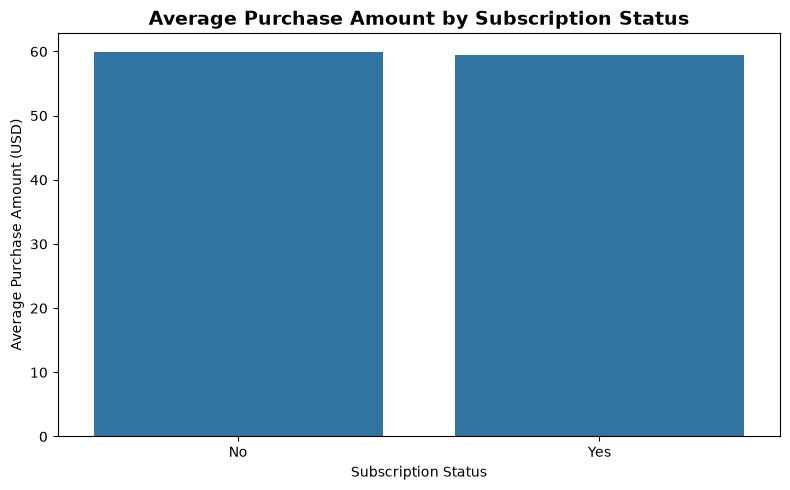

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=subscription_analysis,
    x='Subscription Status',
    y='Average_Purchase_Amount'
)

plt.title('Average Purchase Amount by Subscription Status',
          fontsize=14, fontweight='bold')

plt.xlabel('Subscription Status')
plt.ylabel('Average Purchase Amount (USD)')

plt.tight_layout()
plt.show()

In [19]:
# Payment method analysis

payment_analysis = df_clean.groupby('Payment Method').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

payment_analysis['Average_Purchase_Amount'] = (
    payment_analysis['Average_Purchase_Amount'].round(2)
)

payment_analysis = payment_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

payment_analysis

,Payment Method,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
2,Credit Card,671,40310,60.07
4,PayPal,677,40109,59.25
1,Cash,670,40002,59.70
3,Debit Card,636,38742,60.92
5,Venmo,634,37374,58.95
0,Bank Transfer,612,36544,59.71


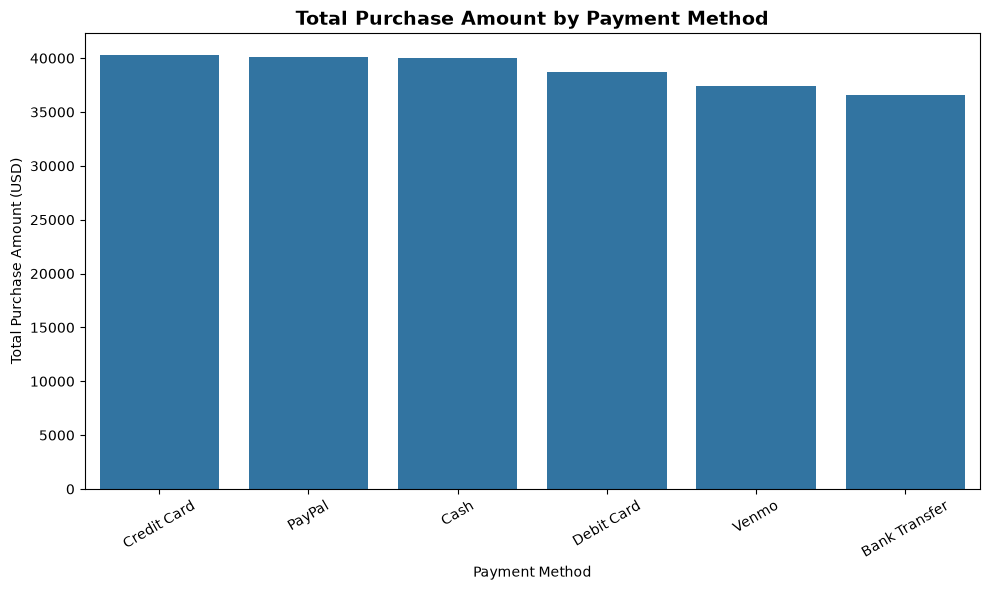

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=payment_analysis,
    x='Payment Method',
    y='Total_Purchase_Amount'
)

plt.title('Total Purchase Amount by Payment Method',
          fontsize=14, fontweight='bold')

plt.xlabel('Payment Method')
plt.ylabel('Total Purchase Amount (USD)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [21]:
# Shopping frequency analysis

frequency_analysis = df_clean.groupby('Frequency of Purchases').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

frequency_analysis['Average_Purchase_Amount'] = (
    frequency_analysis['Average_Purchase_Amount'].round(2)
)

frequency_analysis = frequency_analysis.sort_values(
    by='Total_Customers',
    ascending=False
)

frequency_analysis

,Frequency of Purchases,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
2,Every 3 Months,584,35088,60.08
0,Annually,572,34419,60.17
5,Quarterly,563,33771,59.98
4,Monthly,553,32810,59.33
1,Bi-Weekly,547,33200,60.69
3,Fortnightly,542,32007,59.05
6,Weekly,539,31786,58.97


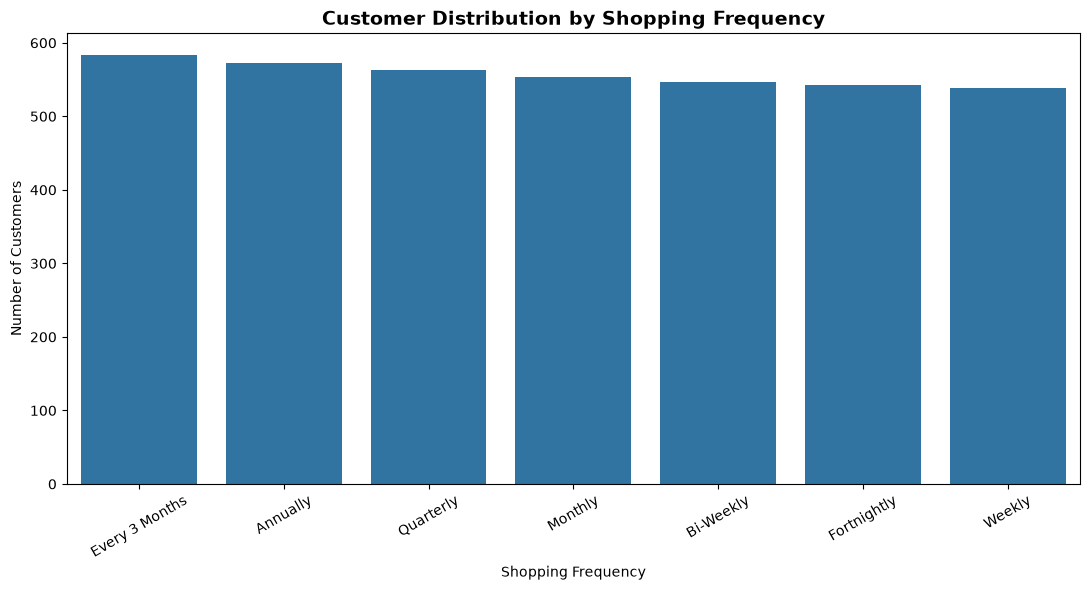

In [22]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=frequency_analysis,
    x='Frequency of Purchases',
    y='Total_Customers'
)

plt.title('Customer Distribution by Shopping Frequency',
          fontsize=14, fontweight='bold')

plt.xlabel('Shopping Frequency')
plt.ylabel('Number of Customers')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [23]:
# Product popularity analysis

product_analysis = df_clean.groupby('Item Purchased').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

product_analysis['Average_Purchase_Amount'] = (
    product_analysis['Average_Purchase_Amount'].round(2)
)

product_analysis = product_analysis.sort_values(
    by='Total_Customers',
    ascending=False
)

product_analysis

,Item Purchased,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
2,Blouse,171,10410,60.88
13,Pants,171,10090,59.01
12,Jewelry,171,10010,58.54
16,Shirt,169,10332,61.14
5,Dress,166,10320,62.17
23,Sweater,164,9462,57.70
10,Jacket,163,9249,56.74
1,Belt,161,9635,59.84
4,Coat,161,9275,57.61
22,Sunglasses,161,9649,59.93


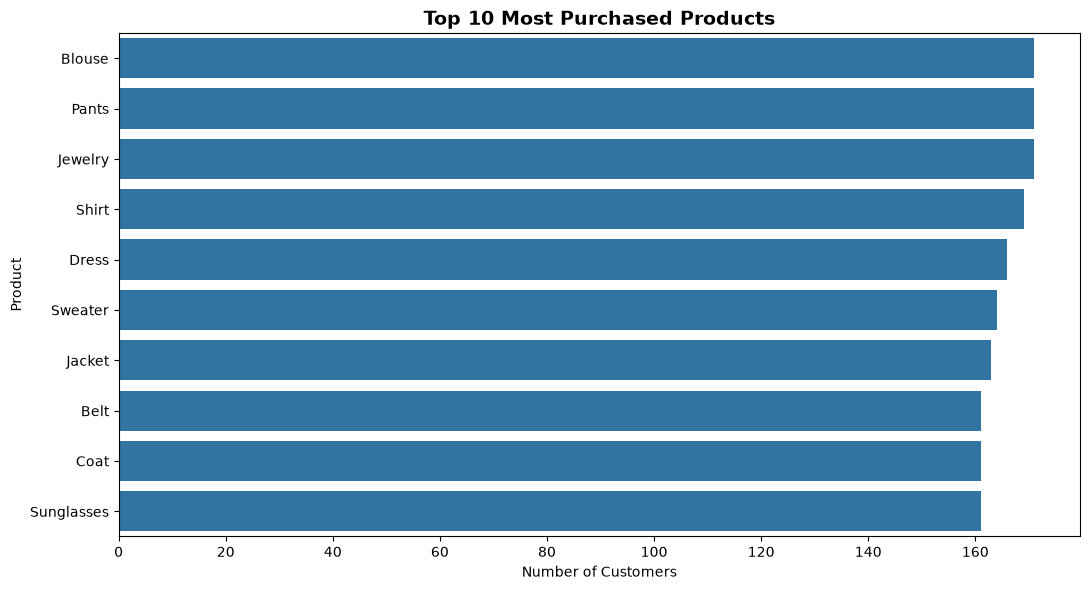

In [24]:
# Select the top 10 products
top_products = product_analysis.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_products,
    x='Total_Customers',
    y='Item Purchased'
)

plt.title(
    'Top 10 Most Purchased Products',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Customers')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [25]:
# Seasonal shopping analysis

season_analysis = df_clean.groupby('Season').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

season_analysis['Average_Purchase_Amount'] = (
    season_analysis['Average_Purchase_Amount'].round(2)
)

season_analysis = season_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

season_analysis

,Season,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
0,Fall,975,60018,61.56
1,Spring,999,58679,58.74
3,Winter,971,58607,60.36
2,Summer,955,55777,58.41


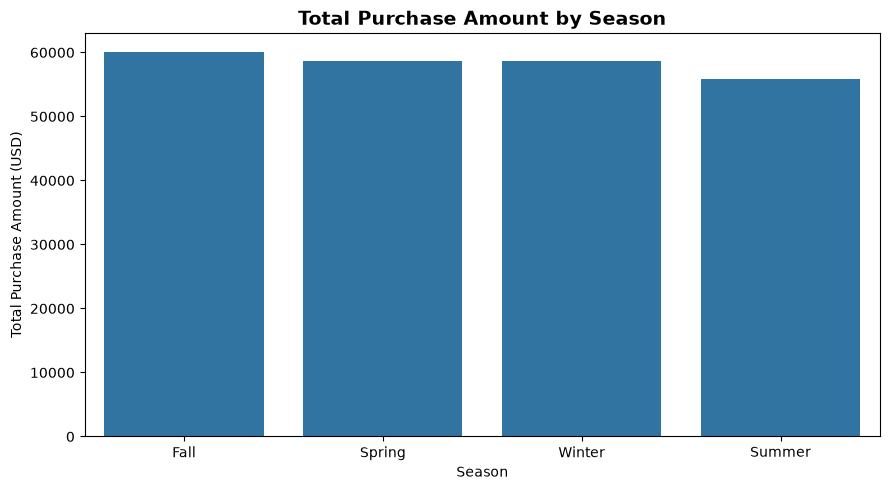

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=season_analysis,
    x='Season',
    y='Total_Purchase_Amount'
)

plt.title(
    'Total Purchase Amount by Season',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Season')
plt.ylabel('Total Purchase Amount (USD)')

plt.tight_layout()
plt.show()

In [27]:
# Age group vs product category analysis

age_category_analysis = df_clean.groupby(
    ['Age Group', 'Category'],
    observed=True
).agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

age_category_analysis['Average_Purchase_Amount'] = (
    age_category_analysis['Average_Purchase_Amount'].round(2)
)

age_category_analysis

,Age Group,Category,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
0,18-25,Accessories,172,10511,61.11
1,18-25,Clothing,269,16221,60.30
2,18-25,Footwear,79,4849,61.38
3,18-25,Outerwear,51,3049,59.78
4,26-35,Accessories,243,14499,59.67
5,26-35,Clothing,337,19942,59.18
6,26-35,Footwear,108,6919,64.06
7,26-35,Outerwear,54,2982,55.22
8,36-45,Accessories,249,14874,59.73
9,36-45,Clothing,319,19061,59.75


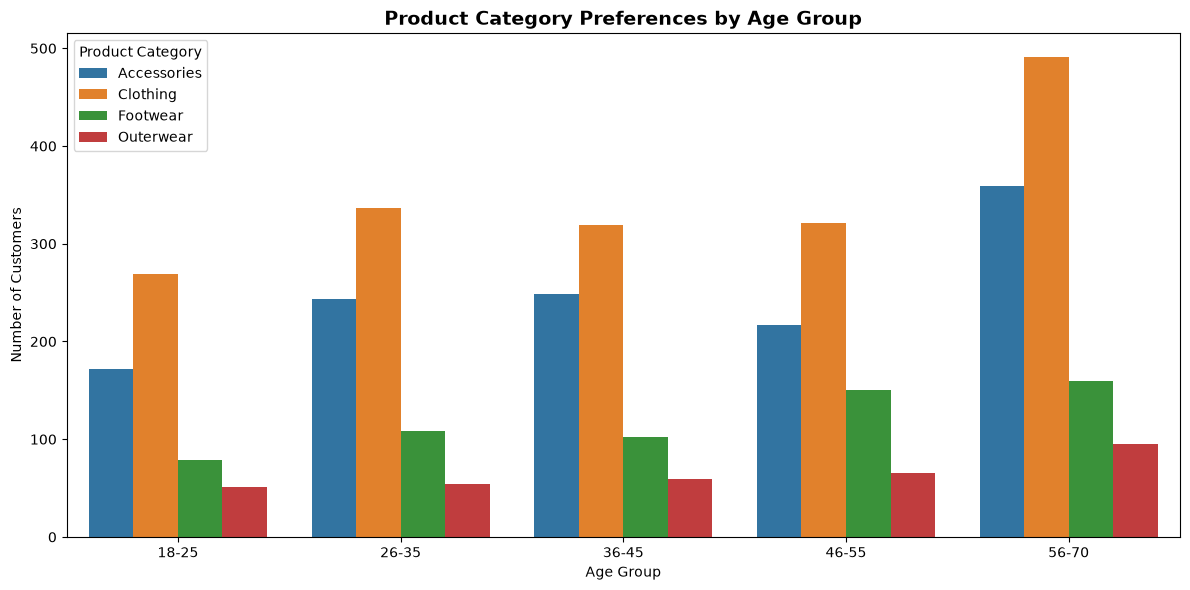

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=age_category_analysis,
    x='Age Group',
    y='Total_Customers',
    hue='Category'
)

plt.title(
    'Product Category Preferences by Age Group',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.legend(title='Product Category')

plt.tight_layout()
plt.show()

In [29]:
# Customer review rating analysis by category

rating_analysis = df_clean.groupby('Category').agg(
    Total_Reviews=('Review Rating', 'count'),
    Average_Review_Rating=('Review Rating', 'mean'),
    Lowest_Rating=('Review Rating', 'min'),
    Highest_Rating=('Review Rating', 'max')
).reset_index()

rating_analysis['Average_Review_Rating'] = (
    rating_analysis['Average_Review_Rating'].round(2)
)

rating_analysis = rating_analysis.sort_values(
    by='Average_Review_Rating',
    ascending=False
)

rating_analysis

,Category,Total_Reviews,Average_Review_Rating,Lowest_Rating,Highest_Rating
2,Footwear,594,3.79,2.5,5.0
0,Accessories,1229,3.77,2.5,5.0
3,Outerwear,322,3.75,2.5,5.0
1,Clothing,1718,3.72,2.5,5.0


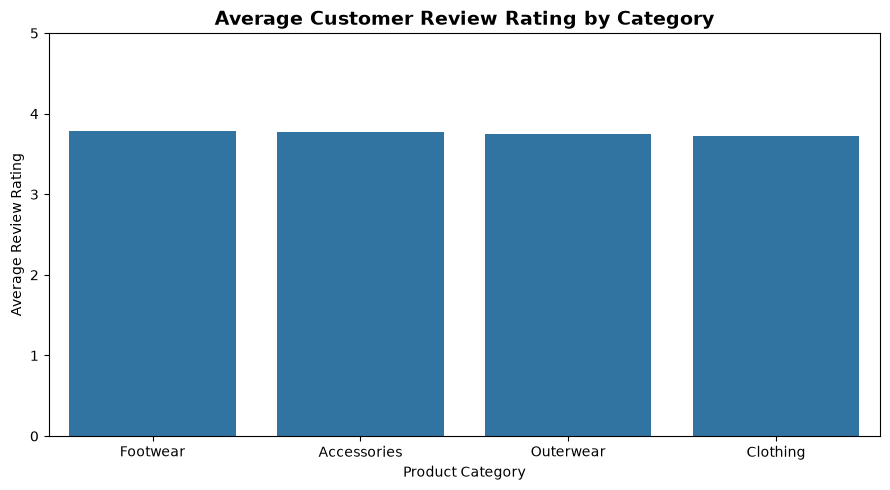

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rating_analysis,
    x='Category',
    y='Average_Review_Rating'
)

plt.title(
    'Average Customer Review Rating by Category',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Product Category')
plt.ylabel('Average Review Rating')
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [31]:
# Discount and promotional code analysis

promotion_analysis = df_clean.groupby(
    ['Discount Applied', 'Promo Code Used']
).agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

promotion_analysis['Average_Purchase_Amount'] = (
    promotion_analysis['Average_Purchase_Amount'].round(2)
)

promotion_analysis

,Discount Applied,Promo Code Used,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
0,No,No,2223,133670,60.13
1,Yes,Yes,1677,99411,59.28


In [32]:
# Check discount and promo code combinations

pd.crosstab(
    df_clean['Discount Applied'],
    df_clean['Promo Code Used'],
    margins=True
)

Promo Code Used,No,Yes,All
Discount Applied,,,
No,2223,0,2223
Yes,0,1677,1677
All,2223,1677,3900


In [33]:
# Shipping method analysis

shipping_analysis = df_clean.groupby('Shipping Type').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

shipping_analysis['Average_Purchase_Amount'] = (
    shipping_analysis['Average_Purchase_Amount'].round(2)
)

shipping_analysis = shipping_analysis.sort_values(
    by='Total_Customers',
    ascending=False
)

shipping_analysis

,Shipping Type,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
2,Free Shipping,675,40777,60.41
4,Standard,654,38233,58.46
5,Store Pickup,650,38931,59.89
3,Next Day Air,648,37993,58.63
1,Express,646,39067,60.48
0,2-Day Shipping,627,38080,60.73


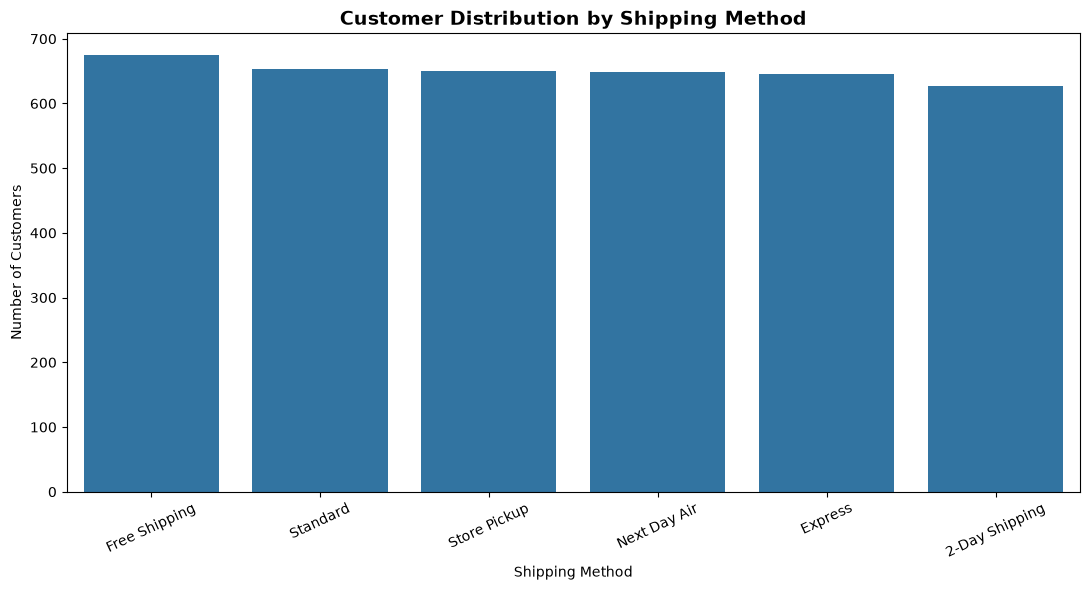

In [34]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=shipping_analysis,
    x='Shipping Type',
    y='Total_Customers'
)

plt.title(
    'Customer Distribution by Shipping Method',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Shipping Method')
plt.ylabel('Number of Customers')

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [35]:
# Location-wise shopping analysis

location_analysis = df_clean.groupby('Location').agg(
    Total_Customers=('Customer ID', 'count'),
    Total_Purchase_Amount=('Purchase Amount (USD)', 'sum'),
    Average_Purchase_Amount=('Purchase Amount (USD)', 'mean')
).reset_index()

location_analysis['Average_Purchase_Amount'] = (
    location_analysis['Average_Purchase_Amount'].round(2)
)

location_analysis = location_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

location_analysis.head(10)

,Location,Total_Customers,Total_Purchase_Amount,Average_Purchase_Amount
25,Montana,96,5784,60.25
12,Illinois,92,5617,61.05
4,California,95,5605,59.00
11,Idaho,93,5587,60.08
27,Nevada,87,5514,63.38
0,Alabama,89,5261,59.11
31,New York,87,5257,60.43
33,North Dakota,83,5220,62.89
47,West Virginia,81,5174,63.88
26,Nebraska,87,5172,59.45


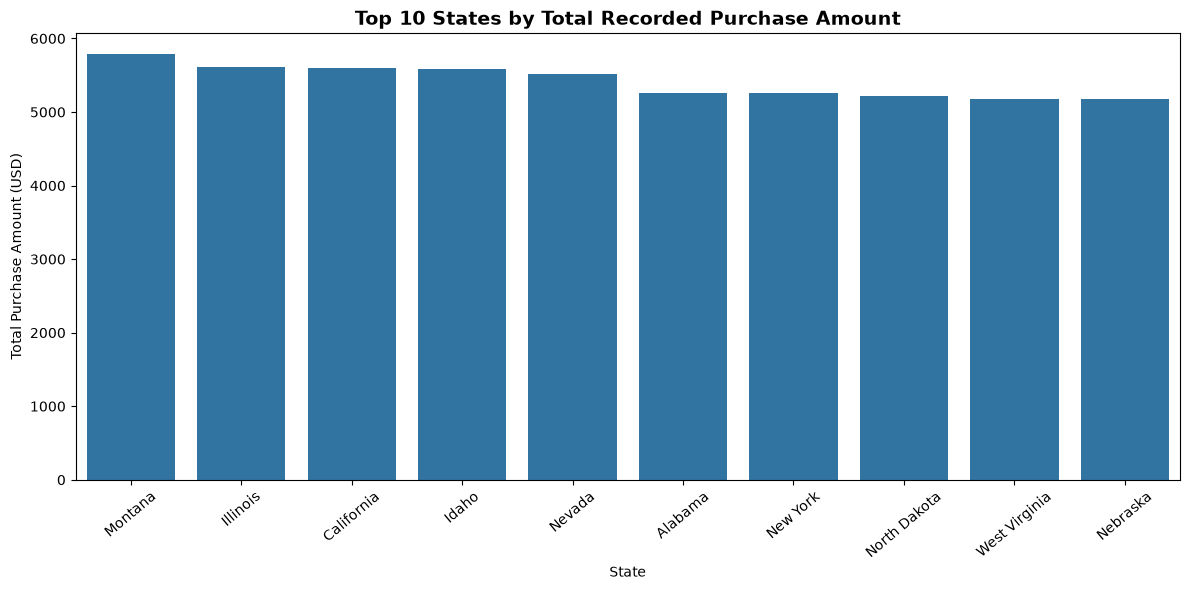

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_analysis.head(10),
    x='Location',
    y='Total_Purchase_Amount'
)

plt.title(
    'Top 10 States by Total Recorded Purchase Amount',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('State')
plt.ylabel('Total Purchase Amount (USD)')

plt.xticks(rotation=40)

plt.tight_layout()
plt.show()

In [37]:
# Export cleaned dataset

df_clean.to_csv(
    "customer_shopping_behavior_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Dataset shape:", df_clean.shape)
print("Total records:", len(df_clean))

Cleaned dataset exported successfully!
Dataset shape: (3900, 20)
Total records: 3900
